<a href="https://colab.research.google.com/github/Ahmed-Rafi07/-MongoDB-connection-string-in-the-.env-file-/blob/main/Hierarchical_Clustering_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from IPython.lib.security import random
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from google.colab import files

# Upload the provided dataset (already uploaded, but keeping for completeness)
# uploaded = files.upload()

# Read the dataset
df = pd.read_csv("customer_spending.csv")

# Use the correct columns found in your uploaded file
features = ["AverageSpend", "AverageFrequency"]
print("Dataset shape: ",df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df[features].isnull().sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features]) #ALWAYS scale first
print("\nScaled data shape: ", X_scaled.shape)

kmeans = KMeans(
    n_clusters = 3,
    n_init = 10,
    random_state = 42
)

# the K-means labels to compare against
df["kmeans"] = kmeans.fit_predict(X_scaled)
print("\nK-means labels created successfully.")
print(df["kmeans"].value_counts().sort_index())

Dataset shape:  (40, 3)

First five rows:


,Name,AverageSpend,AverageFrequency
0,Customer1,88.0,48.0
1,Customer2,95.0,45.5
2,Customer3,92.0,46.8
3,Customer4,85.0,49.2
4,Customer5,90.0,44.0



Missing values:
AverageSpend        0
AverageFrequency    0
dtype: int64

Scaled data shape:  (40, 2)

K-means labels created successfully.
kmeans
0    10
1    20
2    10
Name: count, dtype: int64


Linkage matrix shape:  (39, 4)

First five linkage rows:
[[ 0.          5.          0.04320116  2.        ]
 [31.         37.          0.07254061  2.        ]
 [14.         17.          0.07808024  2.        ]
 [21.         28.          0.08640232  2.        ]
 [23.         29.          0.08640232  2.        ]]


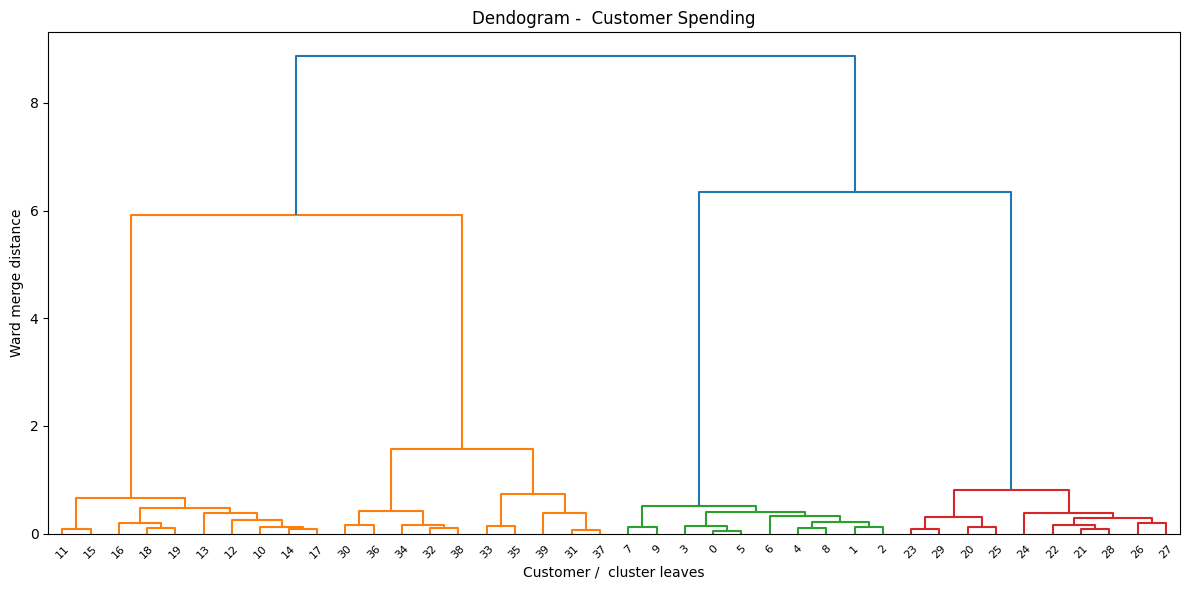

Selected number of clusters:  3
Cut height: 10
Justification: The cut at height 10 is intended to lie inside the large gap between teh final merges within tthe three main branches and their next merge. This gives three clusters.


In [10]:
Z = linkage(X_scaled, method="ward")
print("Linkage matrix shape: ", Z.shape)
print("\nFirst five linkage rows:")
print(Z[:5])

plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.xlabel("Customer /  cluster leaves")
plt.ylabel("Ward merge distance")
plt.title("Dendogram -  Customer Spending")

plt.tight_layout()
plt.show()

# Define the variables to resolve the NameError
K = 3
cut_height = 10

print("Selected number of clusters: ", K)
print("Cut height:", cut_height)
print("Justification: The cut at height 10 is intended to lie inside the large gap between teh final merges within tthe three main branches and their next merge. This gives three clusters.")

In [11]:
from numpy import linalg
agg =  AgglomerativeClustering(
    n_clusters=K,
    linkage="ward"
)

df["hier"] = agg.fit_predict(X_scaled)
print("Hierarchical clustering completed.")
print("\nCluster sizes: ")
print(df["hier"].value_counts().sort_index())

cluster_means = df.groupby("hier")[features].mean().round(2)

print("\nHierarchical cluster profiles:")
display(cluster_means)

Hierarchical clustering completed.

Cluster sizes: 
hier
0    20
1    10
2    10
Name: count, dtype: int64

Hierarchical cluster profiles:


,AverageSpend,AverageFrequency
hier,,
0,56.1,9.75
1,29.2,46.25
2,88.9,46.31


**Cluster 0 — Premium Occasionals**
This cluster represents customers with relatively high annual spending and a high average basket value. Their purchasing pattern suggests that they make valuable purchases, even if they do not shop as frequently as regular customers.
**Cluster 1 — Bargain Hunters**
This cluster represents customers with relatively low annual spending and a low average basket value. Their behaviour suggests that they prefer lower-value purchases and may respond well to discounts and promotional offers.
**Cluster 2 — Steady Regulars**
This cluster represents customers with moderate annual spending and consistent purchase frequency. They may be suitable for loyalty programmes and campaigns designed to encourage repeat purchases.
Note: Confirm these descriptions against the actual cluster means printed by your notebook and revise them if the values indicate a different pattern.
